# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,Liczba braków,Odsetek braków (%)
Cabin,687,0.771044
Age,177,0.198653
Embarked,2,0.002245


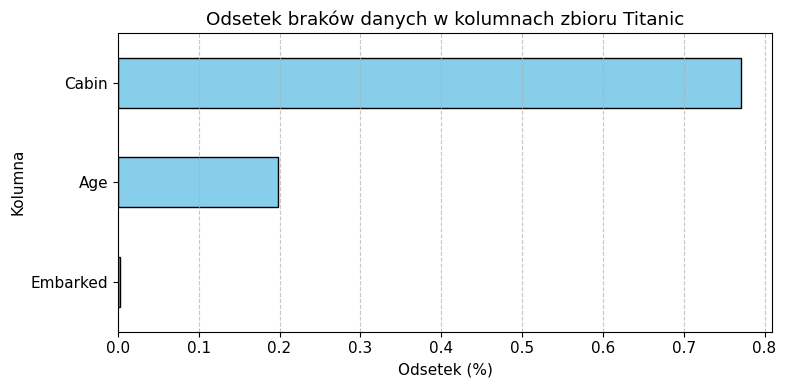

In [11]:
# TODO
braki = titanic.isna().sum()
procent_brakow = titanic.isna().mean()

brakujace_dane = pd.DataFrame({
    'Liczba braków': braki,
    'Odsetek braków (%)': procent_brakow
})

brakujace_dane = brakujace_dane[brakujace_dane['Liczba braków'] > 0].sort_values(by='Liczba braków', ascending=False)
display(brakujace_dane)

plt.figure(figsize=(8,4))
brakujace_dane['Odsetek braków (%)'].sort_values().plot.barh(color='skyblue', edgecolor='black')
plt.title('Odsetek braków danych w kolumnach zbioru Titanic')
plt.xlabel('Odsetek (%)')
plt.ylabel('Kolumna')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

In [ ]:
kolumny = ["Age", "Cabin", "Embarked"]

# TODO

*Twoja odpowiedź:* …

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

In [ ]:
brak_wieku = titanic["Age"].isna()

# TODO

*Twoja odpowiedź:* …

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [ ]:
warianty = {
    "bez zmian": titanic,
    # TODO: pozostałe warianty
}

# TODO: tabela

*Twoja odpowiedź:* …

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

In [ ]:
# TODO

*Twoja odpowiedź:* …

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [ ]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [ ]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO

*Twoja odpowiedź:* …

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [ ]:
# TODO 1

*Twoja odpowiedź:* …

In [ ]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    # TODO: pozostałe kolumny
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
# TODO: typy i liczba braków

### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [ ]:
# TODO

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

In [ ]:
# TODO

*Twoja odpowiedź:* …

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [ ]:
# TODO

### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [ ]:
# TODO

### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

In [ ]:
# TODO

*Twoja odpowiedź:* …

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | | | | |
| `cena_m2` | | | | |
| `rok_budowy` | | | | |
| `pietro` | | | | |
| `parking` | | | | |
| `balkon` | | | | |
| `stan` | | | | |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [ ]:
# TODO

*Twoja odpowiedź:* …